In [25]:
from scipy.io import loadmat
import numpy as np
import pandas as pd
from sklearn.decomposition import NMF
from sklearn.cluster import KMeans
from sklearn.metrics import rand_score, confusion_matrix
from sklearn import metrics
import random
from math import log

In [26]:
def nmf(data, labels):

    number_of_clusters = np.unique(labels).shape[0]
    model = NMF(n_components=number_of_clusters, init="nndsvd", random_state=100, max_iter=10000)
    W = model.fit_transform(data.T)
    H = model.components_

    predicted_labels = np.empty(data.shape[0])

    for j in range(data.shape[0]):
        predicted_labels[j] = np.argmax(H[:, j])
    
    return rand_score(labels, predicted_labels), predicted_labels + 1


In [27]:
def kmeans(data, labels):

    number_of_clusters = np.unique(labels).shape[0]
    model = KMeans(n_clusters=number_of_clusters, random_state=100, algorithm="elkan", init="random")
    model.fit(data)
    predicted_labels = model.labels_

    return rand_score(labels, predicted_labels), predicted_labels

In [28]:
def purity(labels, predicted_labels):

    Confusion_matrix = confusion_matrix(predicted_labels, labels)
    return sum([max(row) for row in Confusion_matrix]) / np.sum(Confusion_matrix)

In [29]:
def _log_(m, n):

    return 0 if m * n == 0 else log(m / n)


In [30]:
def enthropy(labels, predicted_labels):

    number_of_clusters = np.unique(labels).shape[0]
    Confusion_matrix = confusion_matrix(predicted_labels, labels)
    total_enthropy = 0

    for row in Confusion_matrix:

        enthropy_of_cluster = 0
        number_of_points = np.sum(row)

        for col in row:

            enthropy_of_cluster += col * _log_(col, number_of_points)
        
        total_enthropy += enthropy_of_cluster

    return  -(1 / (len(labels) * log(number_of_clusters))) * total_enthropy

# TDT2

In [31]:
tdt2 = loadmat("TDT2.mat")
document_term_sparse_matrix_tdt2 = tdt2["fea"]
Categories_tdt2 = tdt2["gnd"]

In [32]:
uniqes, counts = np.unique(Categories_tdt2, return_counts=True)

index_of_first_10_category_tdt2 = counts[0:10].sum()
index_of_last_10_category_tdt2 = counts[-10:].sum()

document_term_matrix_tdt2_top_10 = document_term_sparse_matrix_tdt2[:index_of_first_10_category_tdt2]
document_term_matrix_tdt2_last_10 = document_term_sparse_matrix_tdt2[-index_of_last_10_category_tdt2:]

labels_of_tdt2_top_10 = Categories_tdt2[:index_of_first_10_category_tdt2].reshape((index_of_first_10_category_tdt2, ))
labels_of_tdt2_last_10 = Categories_tdt2[-index_of_last_10_category_tdt2:].reshape((index_of_last_10_category_tdt2, ))

In [33]:
counts[0:10].sum()

7456

# Reuters21578 

In [34]:
Reuters21578 = loadmat("Reuters21578.mat")
document_term_sparse_matrix_Reuters21578 = Reuters21578["fea"]
Categories_Reuters21578 = Reuters21578["gnd"]

In [35]:
categories, counts = np.unique(Categories_Reuters21578, return_counts=True)
index_of_Reuters21578 = range(Categories_Reuters21578.shape[0])

In [36]:
percentages = [0.05, 0.1] + [0.4] * 8
array_of_top_10_reuters = np.empty((0,), dtype=np.uint16)
last_ind = 0

for i in range(10):

    cat = random.sample(index_of_Reuters21578[last_ind:counts[i] + last_ind], round(percentages[i] * counts[i]))
    array_of_top_10_reuters = np.concatenate((array_of_top_10_reuters, cat))
    last_ind = counts[i] + last_ind


In [37]:
document_term_matrix_Reuters21578_top_10 = document_term_sparse_matrix_Reuters21578[array_of_top_10_reuters]
labels_of_top_Reuters21578_10 = Categories_Reuters21578.reshape((Categories_Reuters21578.shape[0], ))[array_of_top_10_reuters]

In [38]:
percentages = [0.05, 0.1] + [1] * 18
array_of_top_20_reuters = np.empty((0,), dtype=np.uint16)
last_ind = 0

for i in range(20):
    
    cat = random.sample(index_of_Reuters21578[last_ind:counts[i] + last_ind], round(percentages[i] * counts[i]))
    array_of_top_20_reuters = np.concatenate((array_of_top_20_reuters, cat))
    last_ind = counts[i] + last_ind

In [39]:
document_term_matrix_Reuters21578_top_20 = document_term_sparse_matrix_Reuters21578[array_of_top_20_reuters]
labels_of_top_Reuters21578_20 = Categories_Reuters21578.reshape((Categories_Reuters21578.shape[0], ))[array_of_top_20_reuters]

# NMF

In [40]:
score_nmf_TDT2_top_10, predicted_nmf_TDT2_top_10 = nmf(document_term_matrix_tdt2_top_10, labels_of_tdt2_top_10)
score_nmf_TDT2_last_10, predicted_nmf_TDT2_last_10 = nmf(document_term_matrix_tdt2_last_10, labels_of_tdt2_last_10)

purity_of_top_10 = purity(labels_of_tdt2_top_10, predicted_nmf_TDT2_top_10)
purity_of_last_10 = purity(labels_of_tdt2_last_10, predicted_nmf_TDT2_last_10)

entropy_top_10 = enthropy(labels_of_tdt2_top_10, predicted_nmf_TDT2_top_10)
entropy_last_10 = enthropy(labels_of_tdt2_last_10, predicted_nmf_TDT2_last_10)

In [41]:
score_reuters_top_10, predicted_nmf_reuters_top_10 = nmf(document_term_matrix_Reuters21578_top_10, labels_of_top_Reuters21578_10)
score_reuters_top_20, predicted_nmf_reuters_top_20 = nmf(document_term_matrix_Reuters21578_top_20, labels_of_top_Reuters21578_20)

purity_nmf_of_reuters_top_10 = purity(labels_of_top_Reuters21578_10, predicted_nmf_reuters_top_10)
purity_nmf_of_reuters_top_20 = purity(labels_of_top_Reuters21578_20, predicted_nmf_reuters_top_20)

entropy_reuters_top_10 = enthropy(labels_of_top_Reuters21578_10, predicted_nmf_reuters_top_10)
entropy_reuters_top_20 = enthropy(labels_of_top_Reuters21578_20, predicted_nmf_reuters_top_20)

# Kmeans

In [42]:
score_TDT2_top_10, predicted_km_TDT2_top_10 = kmeans(document_term_matrix_tdt2_top_10, labels_of_tdt2_top_10)
score_TDT2_last_10, predicted_km_TDT2_last_10 = kmeans(document_term_matrix_tdt2_last_10, labels_of_tdt2_last_10)

purity_km_of_top_10 = purity(labels_of_tdt2_top_10, predicted_km_TDT2_top_10)
purity_km_of_last_10 = purity(labels_of_tdt2_last_10, predicted_km_TDT2_last_10)

entropy_km_top_10 = enthropy(labels_of_tdt2_top_10, predicted_km_TDT2_top_10)
entropy_km_last_10 = enthropy(labels_of_tdt2_last_10, predicted_km_TDT2_last_10)

In [43]:
score_km_reuters_top_10, predicted_km_reuters_top_10 = kmeans(document_term_matrix_Reuters21578_top_10, labels_of_top_Reuters21578_10)
score_km_reuters_top_20, predicted_km_reuters_top_20 = kmeans(document_term_matrix_Reuters21578_top_20, labels_of_top_Reuters21578_20)

purity_of_reuters_top_10 = purity(labels_of_top_Reuters21578_10, predicted_km_reuters_top_10)
purity_of_reuters_top_20 = purity(labels_of_top_Reuters21578_20, predicted_km_reuters_top_20)

entropy_km_reuters_top_10 = enthropy(labels_of_top_Reuters21578_10, predicted_km_reuters_top_10)
entropy_km_reuters_top_20 = enthropy(labels_of_top_Reuters21578_20, predicted_km_reuters_top_20)

# Results aggregated

In [44]:
dataFrame_of_results = pd.DataFrame({"DataSets" : ["TDT2_TOP_10", "TDT2_LAST_10", "REUTERS21578_TOP_10", "REUTERS21578_TOP_20"],
                                    "" : ["|", "|", "|", "|"],
                                    "NMF_Score" : [score_nmf_TDT2_top_10, score_nmf_TDT2_last_10, score_reuters_top_10, score_reuters_top_20],
                                    "NMF_Purity" : [purity_of_top_10, purity_of_last_10, purity_nmf_of_reuters_top_10, purity_nmf_of_reuters_top_20],
                                    "NMF_Enthropy" : [entropy_top_10, entropy_last_10, entropy_reuters_top_10, entropy_reuters_top_20],
                                    " " : ["|", "|", "|", "|"],
                                    "KMeans_Score" : [score_TDT2_top_10, score_TDT2_last_10, score_km_reuters_top_10, score_km_reuters_top_20],
                                    "KMeans_Purity" : [purity_km_of_top_10, purity_km_of_last_10, purity_of_reuters_top_10, purity_of_reuters_top_20],
                                    "KMeans_Enthropy" : [entropy_km_top_10, entropy_km_last_10, entropy_km_reuters_top_10, entropy_km_reuters_top_20]})

In [45]:
dataFrame_of_results

,DataSets,,NMF_Score,NMF_Purity,NMF_Enthropy,,KMeans_Score,KMeans_Purity,KMeans_Enthropy
0,TDT2_TOP_10,|,0.901644,0.837849,0.237208,|,0.629939,0.553514,0.538190
1,TDT2_LAST_10,|,0.947284,0.823890,0.233210,|,0.680921,0.537519,0.532209
2,REUTERS21578_TOP_10,|,0.879184,0.679680,0.410683,|,0.563086,0.462462,0.690590
3,REUTERS21578_TOP_20,|,0.911326,0.609323,0.418206,|,0.674175,0.372525,0.651347


# Visualization

In [46]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

In [47]:
pca_tdt2_top_10 = PCA(n_components=2).fit_transform(np.asarray(document_term_matrix_tdt2_top_10.todense()))
pca_tdt2_last_10 = PCA(n_components=2).fit_transform(np.asarray(document_term_matrix_tdt2_last_10.todense()))

pca_reuters_top_10 = PCA(n_components=2).fit_transform(np.asarray(document_term_matrix_Reuters21578_top_10.todense()))
pca_reuters_top_20 = PCA(n_components=2).fit_transform(np.asarray(document_term_matrix_Reuters21578_top_20.todense()))

In [48]:
tsne_tdt2_top_10 = TSNE(n_components=2).fit_transform(np.asarray(document_term_matrix_tdt2_top_10.todense()))
tsne_tdt2_last_10 = TSNE(n_components=2).fit_transform(np.asarray(document_term_matrix_tdt2_last_10.todense()))

tsne_reuters_top_10 = TSNE(n_components=2).fit_transform(np.asarray(document_term_matrix_Reuters21578_top_10.todense()))
tsne_reuters_top_20 = TSNE(n_components=2).fit_transform(np.asarray(document_term_matrix_Reuters21578_top_20.todense()))

c:\Users\mahan\anaconda3\lib\site-packages\sklearn\manifold\_t_sne.py:780: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  warnings.warn(
c:\Users\mahan\anaconda3\lib\site-packages\sklearn\manifold\_t_sne.py:790: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  warnings.warn(


In [ ]:
pca_data = [(pca_tdt2_top_10, predicted_nmf_TDT2_top_10, score_nmf_TDT2_top_10, "tdt2_top_10"),
            (pca_tdt2_last_10, predicted_nmf_TDT2_last_10, score_nmf_TDT2_last_10, "tdt2_top_20"),
            (pca_reuters_top_10, predicted_nmf_reuters_top_10, score_reuters_top_10, "reuters_top_10"),
            (pca_reuters_top_20, predicted_nmf_reuters_top_20, score_reuters_top_20, "reuters_top_20")]

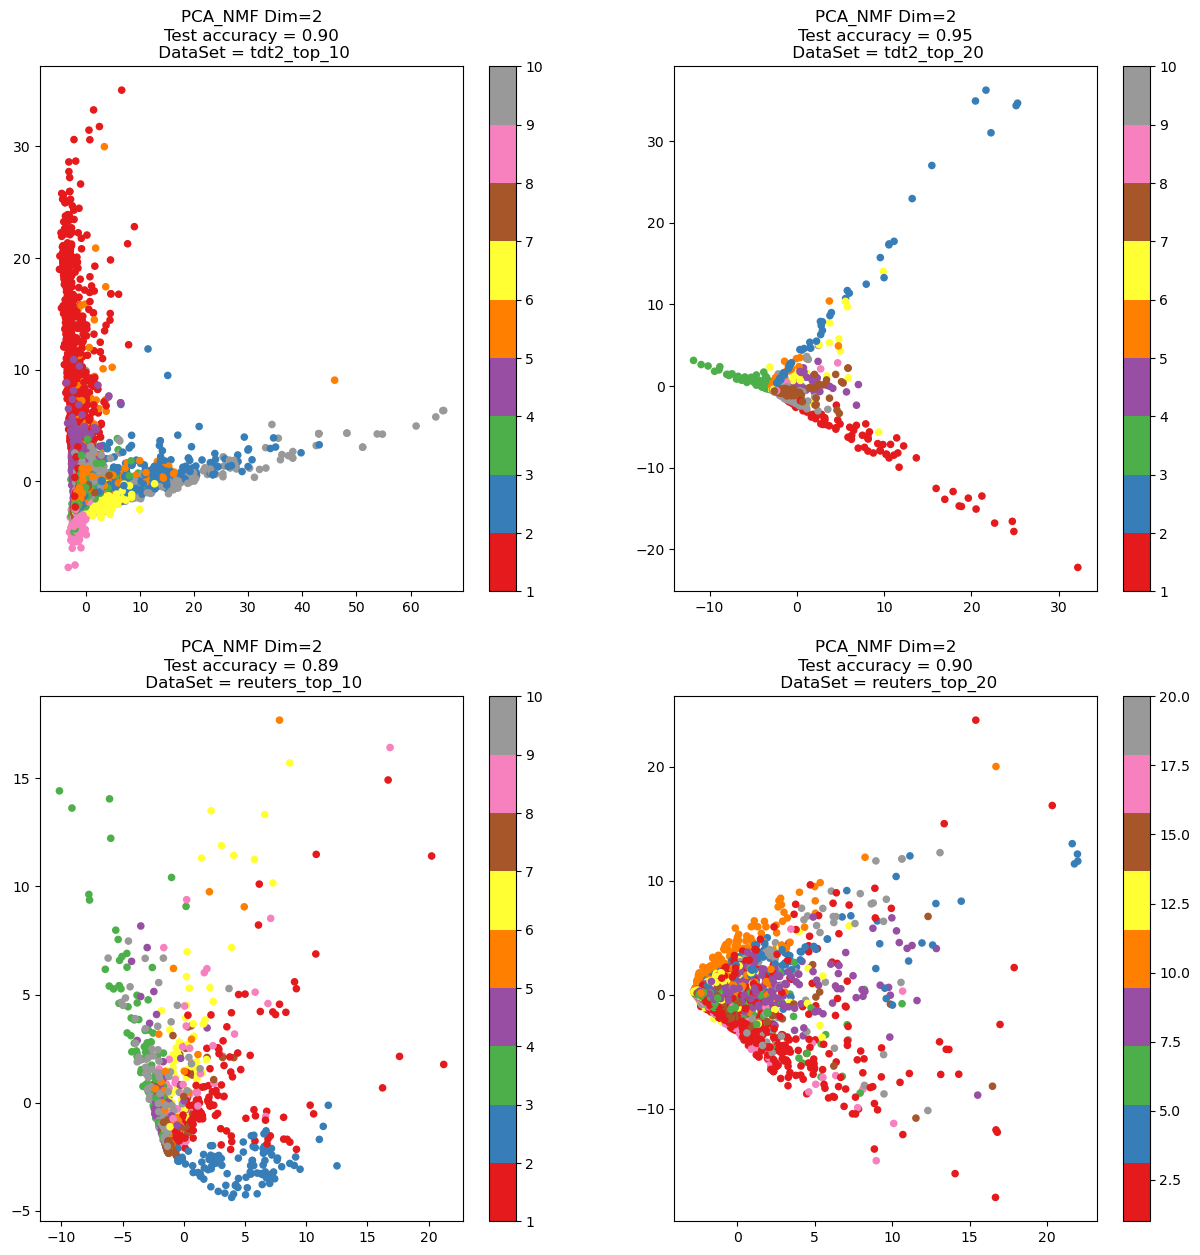

In [ ]:
plt.figure(figsize=(15, 15))

for i, (data, pr_label, score, name) in enumerate(pca_data):

    plt.subplot(2, 2, i + 1, aspect='auto')
    plt.scatter(data[:, 0], data[:, 1], c=pr_label, s=20, cmap='Set1')
    plt.title("{} Dim={}\nTest accuracy = {:.2f}\n DataSet = {}".format("PCA_NMF", 2, score, name))
    plt.colorbar()

plt.savefig("pca.jpg")

In [ ]:
pca_data_kmeans = [(pca_tdt2_top_10, predicted_km_TDT2_top_10, score_TDT2_top_10, "tdt2_top_10"),
            (pca_tdt2_last_10, predicted_km_TDT2_last_10, score_TDT2_last_10, "tdt2_top_20"),
            (pca_reuters_top_10, predicted_km_reuters_top_10, score_km_reuters_top_10, "reuters_top_10"),
            (pca_reuters_top_20, predicted_km_reuters_top_20, score_km_reuters_top_20, "reuters_top_20")]

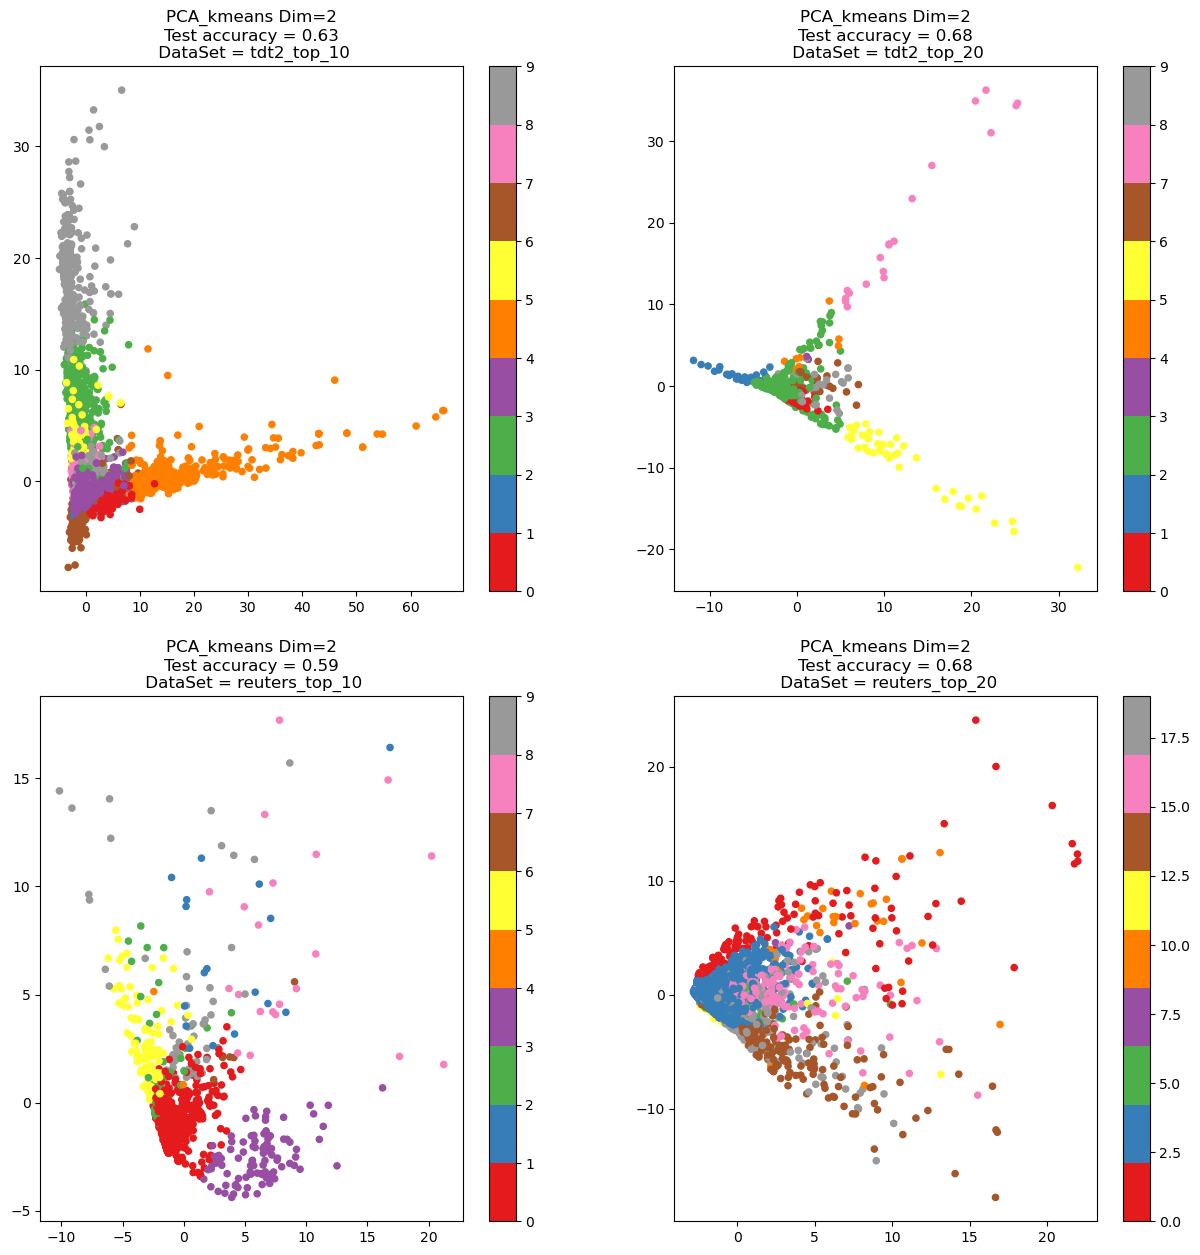

In [ ]:
plt.figure(figsize=(15, 15))

for i, (data, pr_label, score, name) in enumerate(pca_data_kmeans):

    plt.subplot(2, 2, i + 1, aspect='auto')
    plt.scatter(data[:, 0], data[:, 1], c=pr_label, s=20, cmap='Set1')
    plt.title("{} Dim={}\nTest accuracy = {:.2f}\n DataSet = {}".format("PCA_kmeans", 2, score, name))
    plt.colorbar()

plt.savefig("pca_kmeans.jpg")

In [ ]:
tsne_data = [(tsne_tdt2_top_10, predicted_nmf_TDT2_top_10, score_nmf_TDT2_top_10, "tdt2_top_10"),
            (tsne_tdt2_last_10, predicted_nmf_TDT2_last_10, score_nmf_TDT2_last_10, "tdt2_top_20"),
            (tsne_reuters_top_10, predicted_nmf_reuters_top_10, score_reuters_top_10, "reuters_top_10"),
            (tsne_reuters_top_20, predicted_nmf_reuters_top_20, score_reuters_top_20, "reuters_top_20")]

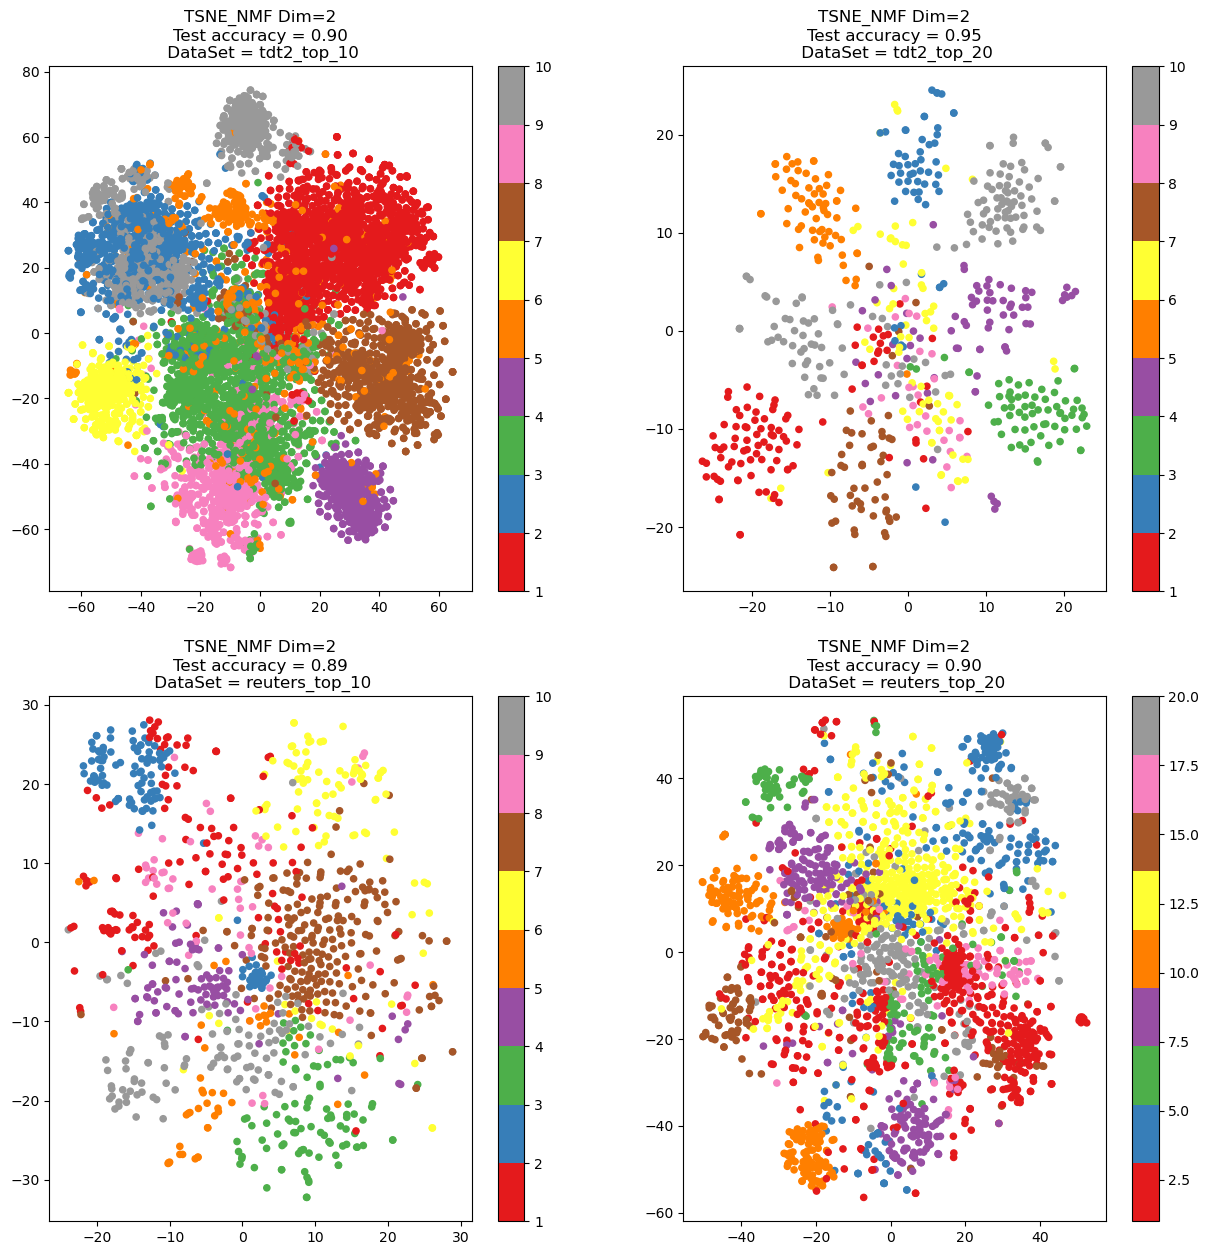

In [ ]:
plt.figure(figsize=(15, 15))

for i, (data, pr_label, score, name) in enumerate(tsne_data):

    plt.subplot(2, 2, i + 1, aspect='auto')
    plt.scatter(data[:, 0], data[:, 1], c=pr_label, s=20, cmap='Set1')
    plt.title("{} Dim={}\nTest accuracy = {:.2f}\n DataSet = {}".format("TSNE_NMF", 2, score, name))
    plt.colorbar()

plt.savefig("tsne.jpg")

In [ ]:
tsne_data_kmeans = [(tsne_tdt2_top_10, predicted_km_TDT2_top_10, score_TDT2_top_10, "tdt2_top_10"),
            (tsne_tdt2_last_10, predicted_km_TDT2_last_10, score_TDT2_last_10, "tdt2_top_20"),
            (tsne_reuters_top_10, predicted_km_reuters_top_10, score_km_reuters_top_10, "reuters_top_10"),
            (tsne_reuters_top_20, predicted_km_reuters_top_20, score_km_reuters_top_20, "reuters_top_20")]

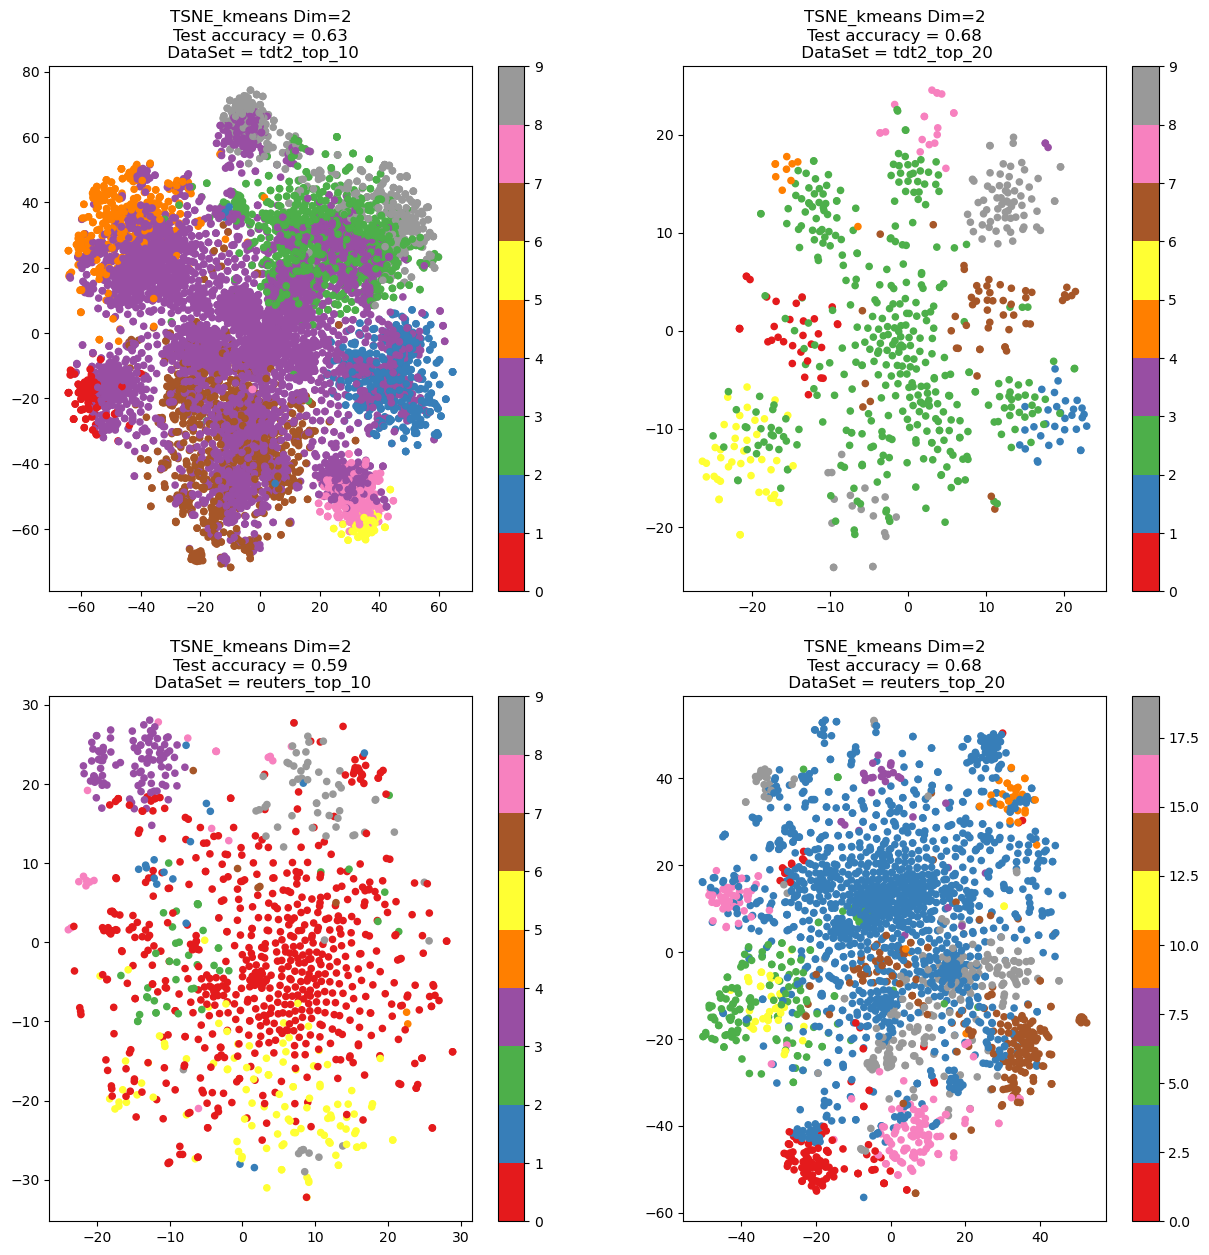

In [ ]:
plt.figure(figsize=(15, 15))

for i, (data, pr_label, score, name) in enumerate(tsne_data_kmeans):

    plt.subplot(2, 2, i + 1, aspect='auto')
    plt.scatter(data[:, 0], data[:, 1], c=pr_label, s=20, cmap='Set1')
    plt.title("{} Dim={}\nTest accuracy = {:.2f}\n DataSet = {}".format("TSNE_kmeans", 2, score, name))
    plt.colorbar()

plt.savefig("tsne_kmeans.jpg")